# Chapter 11: seaborn Basics

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 11.1 seaborn on Top of matplotlib

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
stores = pd.read_csv('stores.csv')
stores.head(4)

,store,region,visitors,daily_revenue,conversion
0,Seattle,Pacific,310,2100,0.021
1,Oakland,Pacific,180,1650,0.027
2,San Francisco,Pacific,420,3300,0.024
3,Portland,Pacific,230,2250,0.032


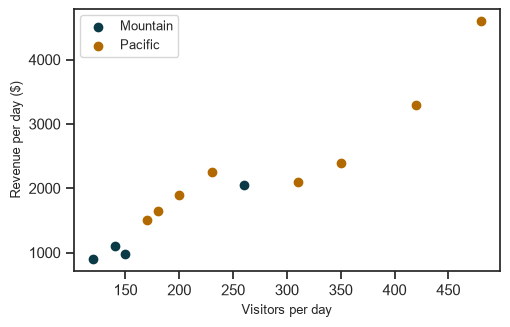

In [3]:
fig, ax = plt.subplots()
for region, group in stores.groupby('region'):
    ax.scatter(group['visitors'], group['daily_revenue'],
               label=region)
ax.legend()
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

### `sns.scatterplot()`

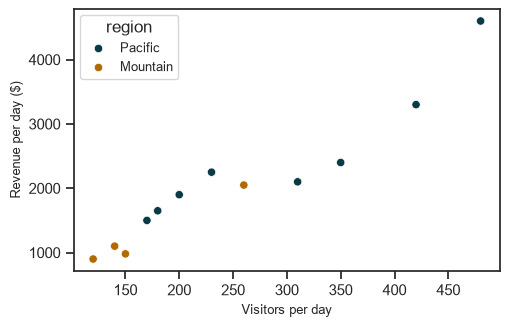

In [4]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [5]:
type(ax)

matplotlib.axes._axes.Axes

## 11.2 Themes: One Line for the Whole Look

### `sns.set_theme()`

In [6]:
plt.rcParams['font.size']

9.5

In [7]:
sns.set_theme()
plt.rcParams['font.size']

12.0

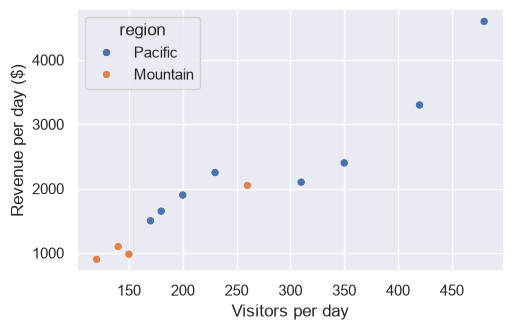

In [8]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [9]:
sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')
plt.rcParams['font.size']

9.5

### `sns.set_style()`

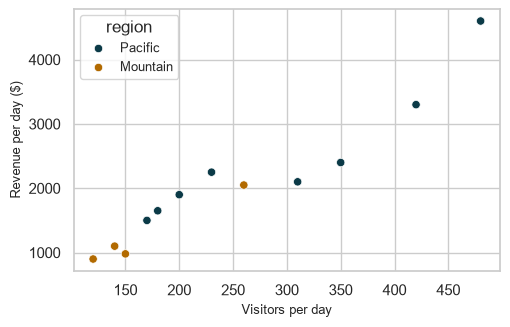

In [10]:
sns.set_style('whitegrid')
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [11]:
sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

### `sns.despine()`

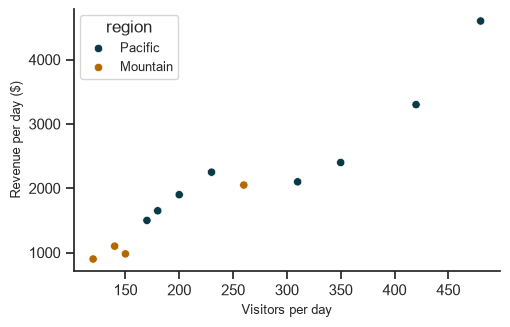

In [12]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
sns.despine()
plt.show()

## 11.3 Color Palettes

### `sns.color_palette()`

In [13]:
sns.color_palette().as_hex()

['#0b3a47', '#b26a00', '#6fb3c2', '#f0c987']

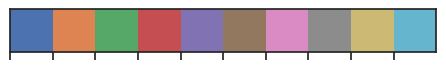

In [14]:
deep = sns.color_palette('deep')
sns.palplot(deep, size=0.55)
plt.show()

### `sns.set_palette()`

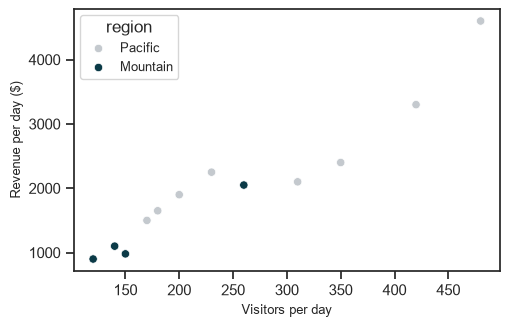

In [15]:
sns.set_palette(['#c4c9ce', '#0b3a47'])
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [16]:
plt.style.use('book.mplstyle')
sns.color_palette().as_hex()

['#0b3a47', '#b26a00', '#6fb3c2', '#f0c987']

## 11.4 Showing More Columns

### `hue=` and `style=`

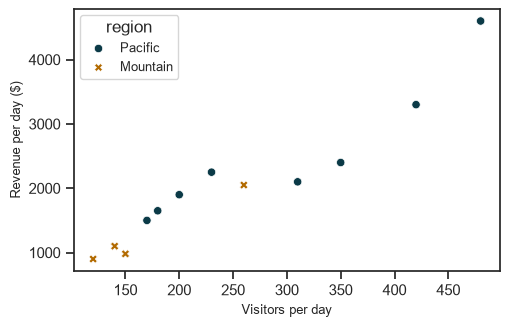

In [17]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region', style='region')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

### `size=`

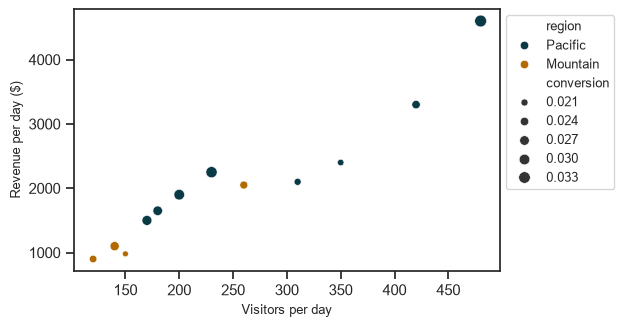

In [18]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     hue='region', size='conversion')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

## 11.5 Long Data and Wide Data

In [19]:
channels = pd.read_csv('channel_monthly.csv')
channels.head(3)

,month,Online,In store,Phone
0,Jan,15100,8900,2600
1,Feb,14600,8100,2500
2,Mar,17800,9300,2700


### `df.melt()`

In [20]:
channels_long = channels.melt(id_vars='month', var_name='channel',
                              value_name='revenue')
channels_long.head(4)

,month,channel,revenue
0,Jan,Online,15100
1,Feb,Online,14600
2,Mar,Online,17800
3,Apr,Online,18900


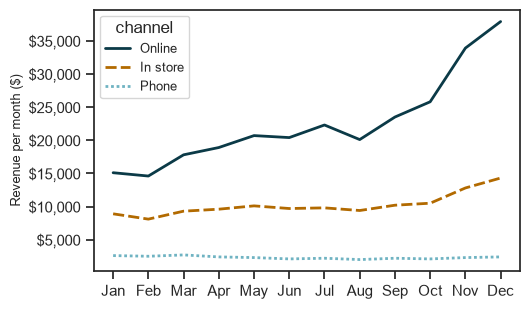

In [21]:
ax = sns.lineplot(data=channels_long, x='month', y='revenue',
                  hue='channel', style='channel')
ax.set(xlabel='', ylabel='Revenue per month ($)')
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.show()

## 11.6 Axes-Level and Figure-Level Functions

### Axes-level functions

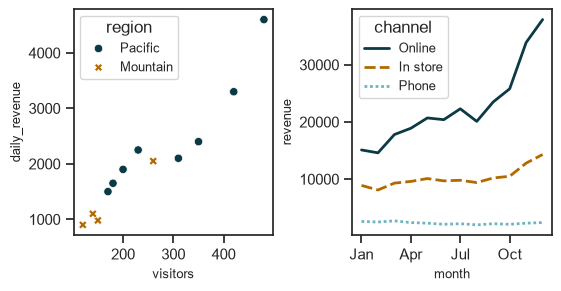

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8),
                         layout='constrained')
sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                hue='region', style='region', ax=axes[0])
sns.lineplot(data=channels_long, x='month', y='revenue',
             hue='channel', style='channel', ax=axes[1])
axes[1].set_xticks([0, 3, 6, 9])
plt.show()

### Figure-level functions

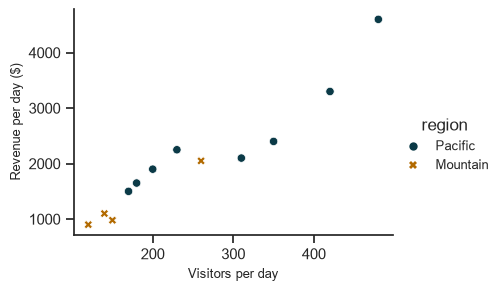

In [23]:
g = sns.relplot(data=stores, kind='scatter', x='visitors',
                y='daily_revenue', hue='region', style='region',
                height=3, aspect=1.4)
g.ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [24]:
type(g)

seaborn.axisgrid.FacetGrid